# Classification d'images : la recette de production, pas a pas

Ce notebook appelle exactement les memes fonctions que les scripts de la recette
(`vtb.tasks.classification.workflow`) et ajoute ce qu'un script ne montre pas : les images,
les courbes, les erreurs, les cartes Grad-CAM. Il s'execute depuis la racine du depot.

Fil : configuration -> catalogue et decoupage -> images pretraitees -> modele du zoo et
strategie de transfert -> entrainement -> test -> erreurs et Grad-CAM -> export ONNX -> prediction.

In [1]:
import json  # json : affiche joliment la carte du modele a la fin
from pathlib import Path  # Path : represente un chemin de fichier, fonctionne sous Windows comme sous Linux

import matplotlib.pyplot as plt  # matplotlib : trace les figures
import pandas as pd  # pandas : tableaux de donnees (catalogue, decoupage, predictions)
import torch  # PyTorch : calcul sur tenseurs (tableaux de nombres, sur CPU ou GPU) et reseaux de neurones
from IPython.display import Image, display  # affiche dans le notebook une image PNG deja enregistree sur disque

from vtb.core.config import load_config  # lit le fichier YAML de l'experience et verifie chaque reglage
from vtb.core.experiment import start  # prepare l'experience : dossier de sortie, journal, graines, choix CPU / GPU

# Grad-CAM : carte de chaleur des zones de l'image qui ont le plus pese dans la decision ; overlay la pose sur l'image
from vtb.explain.gradcam import GradCAM, overlay
from vtb.io.images import read_image  # lit une image en tableau numpy (couleur ou niveaux de gris)
from vtb.models.zoo import list_models  # le "zoo" : la liste des reseaux pre-entraines disponibles
from vtb.preprocess import Pipeline  # enchaine les operations de pretraitement decrites dans le YAML
from vtb.split import load_split, summarize_split  # relit le decoupage (split.csv) ; resume du nombre d'images par partie
from vtb.tasks.classification import workflow  # les etapes de la recette classification (prepare, train, evaluate...)
from vtb.tasks.classification.config import ClassificationConfig  # modele de configuration : les cles autorisees dans le YAML
from vtb.tasks.classification.data import ClassificationDataset  # jeu de donnees PyTorch : donne l'image numero i et sa classe

# La configuration nominale, avec moins d'epoques et une sortie a part pour le notebook.
config = load_config("recipes/classification/configs/resnet18_partial.yaml", ClassificationConfig)  # ResNet-18, strategie partial
config = config.model_copy(  # copie de la config avec quelques valeurs changees (la config d'origine n'est pas modifiee)
    update={  # dict {section: nouvelle valeur de la section}
        "train": config.train.model_copy(update={"epochs": 4}),  # 4 epoques seulement (epoque = un passage sur tout train)
        # sorties dans un dossier a part ; num_workers=0 : chargement des images dans le processus principal (sur dans un notebook)
        "runtime": config.runtime.model_copy(update={"output_dir": "outputs/classification/notebook", "num_workers": 0}),
        "export": config.export.model_copy(update={"openvino": False}),  # pas d'export OpenVINO (Intel) : plus rapide
    }
)
output, device = start(config, "notebook")  # cree le dossier de sortie, le journal, fixe les graines ; device = CPU ou GPU
print(config.model.name, config.model.transfer.strategy, "| sortie", output)  # rappelle le modele, la strategie et le dossier

2026-11-05 19:26:50,455 | INFO | notebook | sortie outputs/classification/notebook | device cpu


resnet18 partial | sortie outputs/classification/notebook


## 1. Catalogue et decoupage

Le decoupage est calcule une fois et relu par toutes les experiences : on ne le refait que
s'il n'existe pas encore.

In [2]:
if not Path(config.split.file).exists():  # si le decoupage n'a pas encore ete fait
    workflow.prepare(config)  # catalogue des images + decoupage train / val / test, enregistre dans split.csv
split = load_split(config.split.file)  # relit le decoupage : une ligne par image (path, label, split...)
print(summarize_split(split))  # nombre d'images par classe et par partie (verifie que chaque classe est presente partout)

split      test  train  val   All
label                            
crazing      45    210   45   300
inclusion    45    210   45   300
patches      45    210   45   300
pitted       45    210   45   300
rolled       45    210   45   300
scratches    45    210   45   300
All         270   1260  270  1800


## 2. Ce que le reseau voit : images apres pretraitement, puis apres augmentation

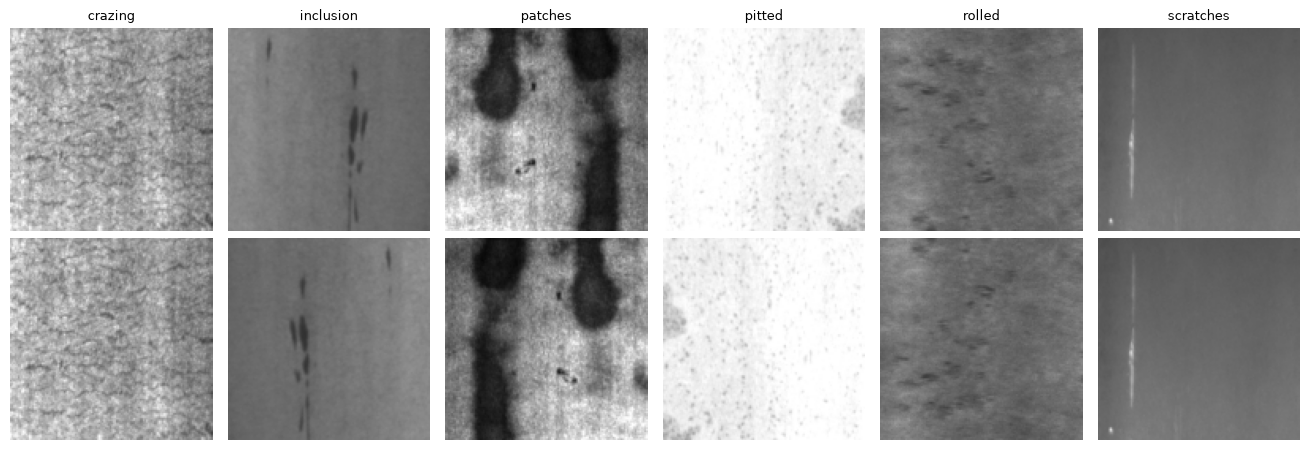

In [3]:
names = sorted(split["label"].unique())  # noms des classes, tries : l'ordre fixe le numero de chaque classe
pipeline = Pipeline(config.preprocess)  # pretraitement du YAML (le meme a l'entrainement, en prediction et a l'export)
dataset = ClassificationDataset(  # jeu de donnees des images de train, pour regarder ce que recoit le reseau
    split[split["split"] == "train"],  # les lignes du catalogue de la partie train
    {n: i for i, n in enumerate(names)},  # nom de classe -> numero (le reseau travaille avec des numeros)
    pipeline,  # pretraitement a appliquer a chaque image
    config.data.color,  # "rgb" ou "gray" : comment lire les images
    None,  # mean = None : pas de normalisation (centrage-reduction des valeurs), pour pouvoir afficher l'image
    None,  # std = None : idem
    # augmentation = modifications aleatoires (retournement, rotation...) appliquees seulement a l'entrainement
    workflow.augmentation_for(config),
)
fig, axes = plt.subplots(2, len(names), figsize=(2.2 * len(names), 4.6))  # grille 2 lignes (pretraite, augmente) x nb de classes
for k, name in enumerate(names):  # pour chaque classe ; k = numero de colonne
    # index (dans le catalogue) de la 1re image de train de cette classe
    index = int(split[(split["split"] == "train") & (split["label"] == name)].index[0])
    position = list(split[split["split"] == "train"].index).index(index)  # sa position dans le jeu de train (0, 1, 2...)
    axes[0, k].imshow(dataset.load(position), cmap="gray")  # 1re ligne : l'image pretraitee (sans augmentation)
    axes[0, k].set_title(name, fontsize=9)  # titre : la classe
    # 2e ligne : dataset[i] renvoie (tenseur, classe) ; tenseur (canaux, hauteur, largeur) remis en (hauteur, largeur, canaux)
    axes[1, k].imshow(dataset[position][0].permute(1, 2, 0).numpy())  # tenseur augmente, avant normalisation
    for ax in axes[:, k]:  # pour les deux cases de cette colonne
        ax.axis("off")  # masque les axes gradues
axes[0, 0].set_ylabel("pretraite")  # etiquette de la 1re ligne
plt.tight_layout()  # resserre les cases
plt.show()  # affiche la figure

## 3. Choisir un modele pre-entraine

Le catalogue donne, pour chaque architecture, ses parametres et sa precision ImageNet. La
commande `python recipes/classification/scripts/list_models.py --latency` ajoute la latence
CPU mesuree sur la machine : c'est elle qui decide en production.

In [4]:
print(list_models().to_string(index=False))  # tableau des modeles du zoo (parametres, precision ImageNet)

              name      source  params_M  imagenet_top1                                                       notes
          resnet18 torchvision     11.69         69.758 le choix par defaut : rapide, robuste, 11,7 M de parametres
          resnet34 torchvision     21.80         73.314                                                            
          resnet50 torchvision     25.56         80.858              plus precis, 2 a 3 fois plus lent que resnet18
   efficientnet_b0 torchvision      5.29         77.692                         tres bon rapport precision / calcul
mobilenet_v3_small torchvision      2.54         67.668                     le plus leger : PC industriel, embarque
mobilenet_v3_large torchvision      5.48         75.274                                                            
     convnext_tiny torchvision     28.59         82.520                    architecture moderne, plus lente sur CPU
    regnet_y_800mf torchvision      6.43         78.828                 

## 4. Entrainer : strategie partial (tete neuve + layer4, taux 10 fois plus faible)

2026-11-05 19:26:55,189 | INFO | classes ['crazing', 'inclusion', 'patches', 'pitted', 'rolled', 'scratches'] | train 1260 | val 270 | entree (128, 128, 3) | mean [0.485, 0.456, 0.406]


2026-11-05 19:26:55,197 | INFO | strategie partial | parametres entrainables 8396806 sur 11179590


2026-11-05 19:28:45,231 | INFO | epoque  1 | train perte 0.2203 acc 0.944 | val perte 0.0243 acc 0.996 | lr 1.0e-03 | 110s | meilleur


2026-11-05 19:30:37,710 | INFO | epoque  2 | train perte 0.0200 acc 0.994 | val perte 0.0110 acc 0.993 | lr 1.0e-03 | 112s | meilleur


2026-11-05 19:32:13,004 | INFO | epoque  3 | train perte 0.0132 acc 0.997 | val perte 0.0105 acc 0.996 | lr 1.0e-03 | 95s | meilleur


2026-11-05 19:33:34,409 | INFO | epoque  4 | train perte 0.0113 acc 0.997 | val perte 0.0040 acc 1.000 | lr 1.0e-03 | 81s | meilleur


2026-11-05 19:33:34,416 | INFO | entrainement : 399.2 s


2026-11-05 19:33:44,417 | INFO | meilleure epoque 4 | val perte 0.0040 acc 1.000 -> outputs/classification/notebook/model.pt


{'strategy': 'partial', 'best_epoch': 4, 'val_loss': 0.003950871083954418, 'val_accuracy': 1.0, 'train_seconds': 399.2, 'trainable_params': 8396806}


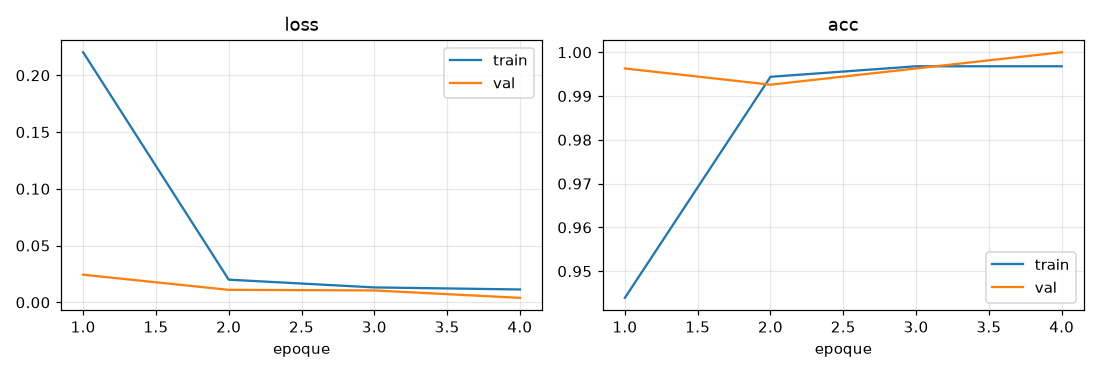

In [5]:
# entraine sur train, garde la meilleure epoque sur val ; renvoie un resume (meilleure epoque, duree, mesures val...)
summary = workflow.train(config, output, device)
print(summary)  # affiche le resume
display(Image(str(output / "curves.png")))  # courbes de perte et de precision par epoque (train et val)

## 5. Tester, une seule fois

2026-11-05 19:33:58,532 | INFO | test : accuracy 0.993 | balanced 0.993 | F1 macro 0.993 | 270 images
              precision    recall  f1-score   support

     crazing      1.000     1.000     1.000        45
   inclusion      0.978     0.978     0.978        45
     patches      1.000     1.000     1.000        45
      pitted      0.978     1.000     0.989        45
      rolled      1.000     1.000     1.000        45
   scratches      1.000     0.978     0.989        45

    accuracy                          0.993       270
   macro avg      0.993     0.993     0.993       270
weighted avg      0.993     0.993     0.993       270



{'accuracy': 0.9926, 'balanced_accuracy': 0.9926, 'f1_macro': 0.9926, 'log_loss': 0.0096}


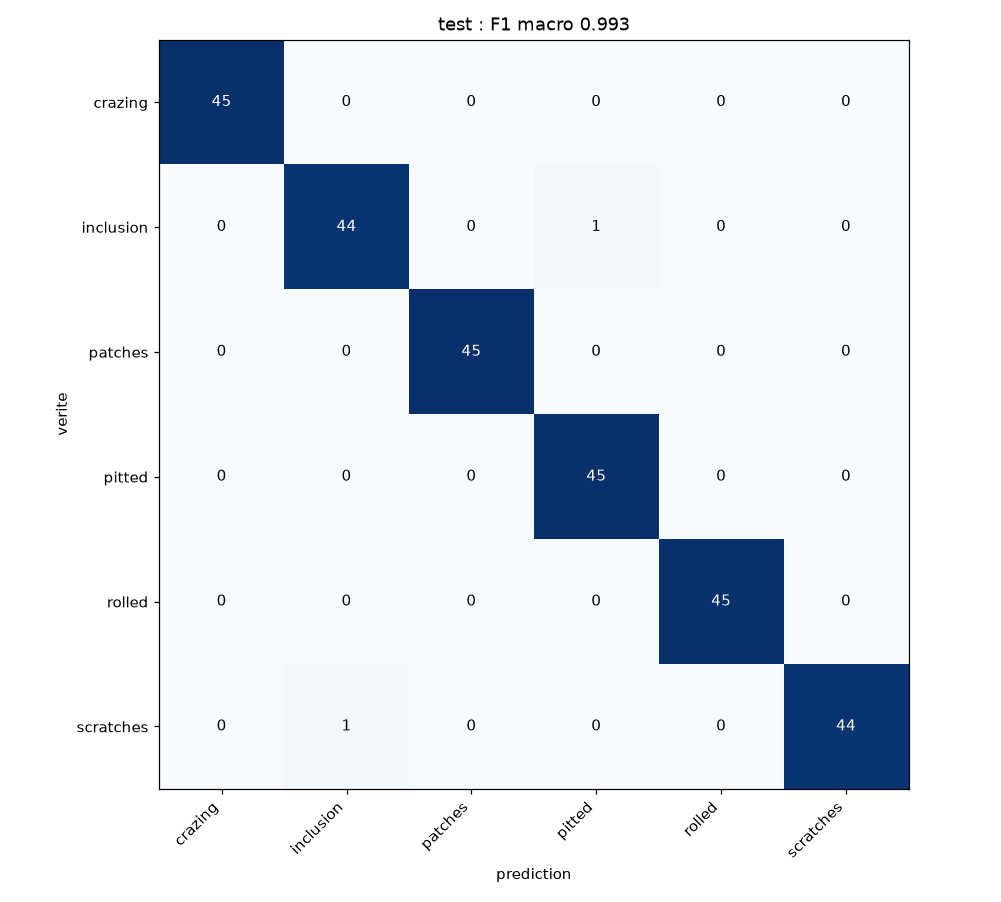

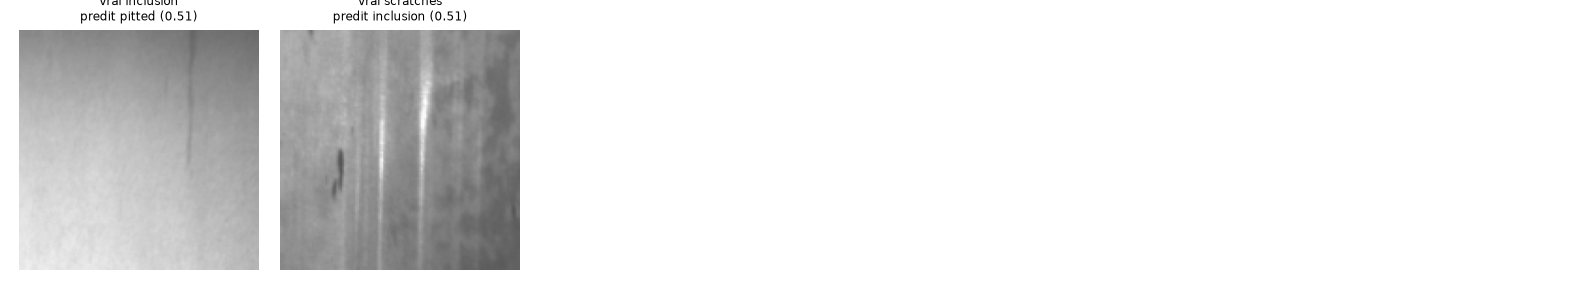

In [6]:
metrics = workflow.evaluate(config, output, device)  # mesures sur le jeu de test (accuracy, F1 macro...)
print({k: round(v, 4) for k, v in metrics.items() if isinstance(v, float)})  # seulement les nombres, arrondis a 4 decimales
display(Image(str(output / "confusion_matrix.png")))  # matrice de confusion : vraie classe en ligne, classe predite en colonne
if (output / "test_errors.png").exists():  # si des images ont ete mal classees (la figure n'existe que dans ce cas)
    display(Image(str(output / "test_errors.png")))  # affiche ces images mal classees

## 6. Ou regarde le modele ? Grad-CAM sur des images de test

La zone chaude doit etre le defaut. Une carte allumee sur un bord ou un coin signale un
modele qui a appris un artefact.

In [7]:
# recharge model.pt sur CPU : le modele, le paquet de reglages sauve avec lui (classes, couleur...) et le pretraitement
model, bundle, pipe = workflow.load_trained(output, torch.device("cpu"))
cam = GradCAM(model, "layer4")  # branche Grad-CAM sur "layer4", le dernier bloc de convolutions de ResNet
test_df = load_split(config.split.file, "test").groupby("label").head(1)  # une image de test par classe
fig, axes = plt.subplots(1, len(test_df), figsize=(2.4 * len(test_df), 2.8))  # une case par image
for ax, (_, row) in zip(axes, test_df.iterrows()):  # pour chaque case et chaque image de test
    image = pipe(read_image(row["path"], bundle["color"]))  # lit l'image et lui applique le pretraitement du modele
    # tenseur normalise comme a l'entrainement ; heat = carte de chaleur [0, 1], cls = numero de la classe predite
    heat, cls = cam(workflow.to_input_tensor(image, bundle))
    ax.imshow(overlay(image, heat))  # image avec la carte de chaleur posee dessus (rouge = zone decisive)
    ax.set_title(f"{row['label']}\npredit {bundle['class_names'][cls]}", fontsize=8)  # vraie classe, puis classe predite
    ax.axis("off")  # masque les axes gradues
cam.close()  # debranche Grad-CAM du modele (retire le crochet pose sur layer4)
plt.tight_layout()  # resserre les cases
plt.show()  # affiche la figure

## 7. Comparer les strategies

Le tableau rassemble les experiences deja lancees par les scripts (une par YAML) ; lancer
`python recipes/classification/scripts/compare.py` apres de nouvelles experiences.

In [8]:
import importlib.util  # importlib.util : charge un fichier .py par son chemin (le script n'est pas un module installe)

spec = importlib.util.spec_from_file_location("compare", "recipes/classification/scripts/compare.py")  # decrit le module
compare = importlib.util.module_from_spec(spec)  # cree un module vide a partir de cette description
spec.loader.exec_module(compare)  # execute le fichier : ses fonctions (dont collect) deviennent disponibles
table = compare.collect(Path("outputs/classification"))  # tableau des experiences deja lancees par les scripts
print(table.to_string(index=False) if len(table) else "aucune experience terminee pour l'instant")  # tableau, ou message si vide

          experience       modele   strategie  params_entraines  meilleure_epoque  temps_s  test_accuracy  test_f1_macro onnx_ms
            notebook     resnet18     partial           8396806                 4    399.2          0.993          0.993        
               quick     resnet18        head              3078                 2     39.7          0.941          0.941    2.75
   resnet18_features     resnet18    features              3078                 1      9.8          0.978          0.978   10.56
       resnet18_full     resnet18        full          11179590                 7    190.9          1.000          1.000    3.98
       resnet18_gray     resnet18     partial           8396806                 9    121.5          1.000          1.000    3.98
       resnet18_head     resnet18        head              3078                 8    131.1          0.959          0.959    4.13
    resnet18_partial     resnet18     partial           8396806                 7    477.9       

## 8. Exporter, puis predire comme en production

In [9]:
# export ONNX (format standard de modele, lisible sans PyTorch) verifie contre PyTorch ; renvoie la carte du modele
card = workflow.export(config, output)
# affiche une partie de la carte : entree attendue, pretraitement, sorties, latences (indent=1 : JSON indente)
print(json.dumps(card.model_dump(include={"input", "preprocess", "outputs", "latency_ms"}), indent=1))

[torch.onnx] Obtain model graph for `ResNet([...]` with `torch.export.export(..., strict=False)`...


[torch.onnx] Obtain model graph for `ResNet([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅


2026-11-05 19:34:06,853 | INFO | ONNX ecrit : outputs/classification/notebook/model.onnx (44.8 Mo)


2026-11-05 19:34:07,294 | INFO | verification ONNX OK : {'output_0_max_abs_diff': '1.00e-05', 'output_0_scale': '9.04e+00', 'batch_size': 3}


2026-11-05 19:34:10,009 | INFO | latence : {'torch_cpu_ms': 94.61, 'batch': 1, 'onnxruntime_cpu_ms': 24.64}


2026-11-05 19:34:10,022 | INFO | carte du modele -> outputs/classification/notebook/model_card.json


{
 "input": {
  "name": "input",
  "layout": "NCHW",
  "height": 128,
  "width": 128,
  "channels": 3,
  "color": "RGB",
  "dtype": "float32",
  "scale": "divide by 255 (8 bits) or 65535 (16 bits)",
  "mean": [
   0.485,
   0.456,
   0.406
  ],
  "std": [
   0.229,
   0.224,
   0.225
  ],
  "resize": "stretch",
  "letterbox_pad_value": null,
  "dynamic_batch": true,
  "read_color": "rgb"
 },
 "preprocess": [
  {
   "name": "resize",
   "size": 128,
   "interpolation": "auto"
  }
 ],
 "outputs": [
  {
   "name": "logits",
   "shape": [
    "batch",
    6
   ],
   "description": "scores avant softmax ; classe = argmax, probabilites = softmax"
  }
 ],
 "latency_ms": {
  "torch_cpu_ms": 94.61,
  "onnxruntime_cpu_ms": 24.64
 }
}


In [10]:
# predit toutes les images du dossier de la 1re classe, comme le ferait predict.py ; renvoie un tableau
predictions = workflow.predict(config, output, device, Path(config.data.root) / names[0])
print(predictions.head(8).to_string(index=False))  # affiche les 8 premieres predictions
# part des images de ce dossier predites dans la bonne classe (moyenne de vrai / faux = proportion de vrai)
print("part predite comme", names[0], ":", round(float((predictions["label"] == names[0]).mean()), 3))
pd.set_option("display.width", 140)  # pandas affichera des tableaux jusqu'a 140 caracteres de large

2026-11-05 19:34:22,836 | INFO | prediction de 300 images : 12.5 s


2026-11-05 19:34:22,846 | INFO | 41.6 ms par image


                                    path   label  probability
  data/raw/neu_cls_flat/crazing/Cr_1.bmp crazing       1.0000
 data/raw/neu_cls_flat/crazing/Cr_10.bmp crazing       0.9999
data/raw/neu_cls_flat/crazing/Cr_100.bmp crazing       1.0000
data/raw/neu_cls_flat/crazing/Cr_101.bmp crazing       0.9999
data/raw/neu_cls_flat/crazing/Cr_102.bmp crazing       1.0000
data/raw/neu_cls_flat/crazing/Cr_103.bmp crazing       1.0000
data/raw/neu_cls_flat/crazing/Cr_104.bmp crazing       0.9999
data/raw/neu_cls_flat/crazing/Cr_105.bmp crazing       0.9999
part predite comme crazing : 1.0
